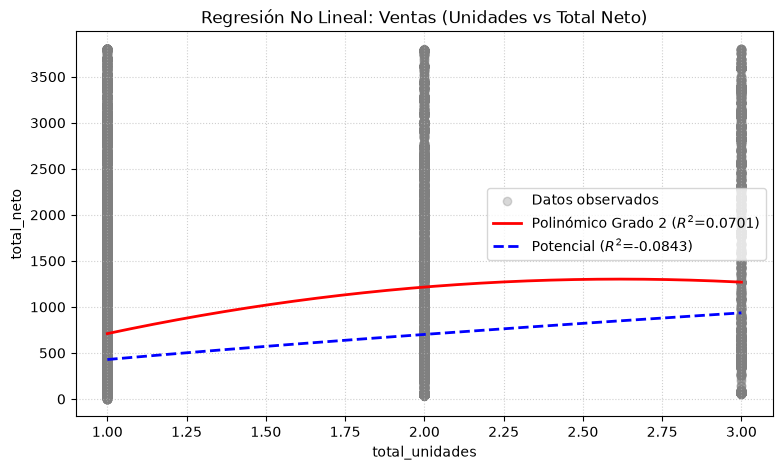

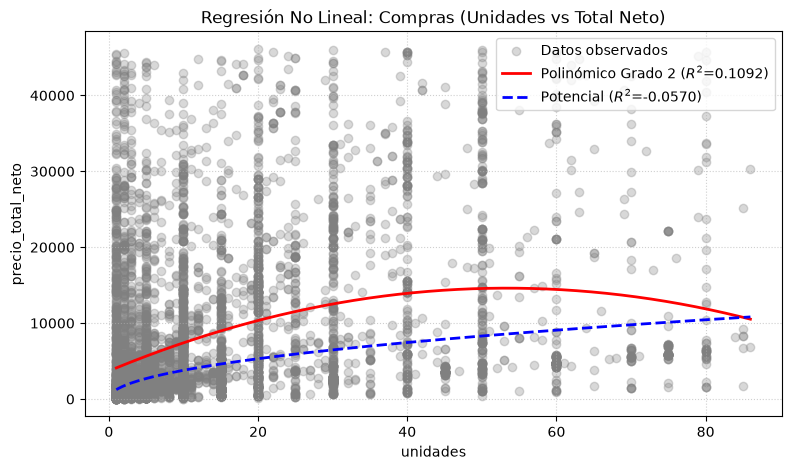


--- TABLA DE COEFICIENTES DE DETERMINACIÓN Y CORRELACIÓN ---
                        Análisis             Modelo  Spearman (r)      R2     RMSE
 Ventas (Unidades vs Total Neto) Polinómico Grado 2        0.2806  0.0701   841.96
 Ventas (Unidades vs Total Neto)          Potencial        0.2806 -0.0843   909.18
Compras (Unidades vs Total Neto) Polinómico Grado 2        0.4122  0.1092  9440.38
Compras (Unidades vs Total Neto)          Potencial        0.4122 -0.0570 10283.64


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import spearmanr

# ---------------------------------------------------------
# 1. CARGA DE DATOS DESDE EXCEL Y HOJAS CORRESPONDIENTES
# ---------------------------------------------------------
# Nombre del archivo principal
archivo_excel = 'Datos_CLV_2026_Tec_v2.xlsx'

# Carga de hojas especificadas
df_ventas = pd.read_excel(archivo_excel, sheet_name='Ventas_CLV_2022_2026')
df_compras = pd.read_excel(archivo_excel, sheet_name='Histórico_Compras')

# ---------------------------------------------------------
# 2. PREPROCESAMIENTO DE DATOS (Nulos y Outliers - Punto 3)
# ---------------------------------------------------------
def preprocesar_datos(df, col_x, col_y):
    # Selección de columnas numéricas y eliminación de nulos
    data = df[[col_x, col_y]].dropna().copy()
    
    # Filtrar valores <= 0 para permitir transformaciones logarítmicas
    data = data[(data[col_x] > 0) & (data[col_y] > 0)]
    
    # Tratamiento de Outliers mediante IQR (Rango Intercuartílico)
    for col in [col_x, col_y]:
        Q1 = data[col].quantile(0.25)
        Q3 = data[col].quantile(0.75)
        IQR = Q3 - Q1
        lim_inf = Q1 - 1.5 * IQR
        lim_sup = Q3 + 1.5 * IQR
        data = data[(data[col] >= lim_inf) & (data[col] <= lim_sup)]
        
    return data

# Preprocesar conjuntos de datos según las columnas del diccionario
datos_ventas = preprocesar_datos(df_ventas, 'total_unidades', 'total_neto')
datos_compras = preprocesar_datos(df_compras, 'unidades', 'precio_total_neto')

# ---------------------------------------------------------
# 3. FUNCIONES PARA MODELOS NO LINEALES (Punto 4)
# ---------------------------------------------------------
def evaluar_modelos(data, col_x, col_y, nombre_analisis):
    X = data[col_x].values
    y = data[col_y].values
    
    # Correlación no lineal de Spearman
    corr_spearman, _ = spearmanr(X, y)
    
    # Modelo 1: Polinómico Grado 2
    coef_poly = np.polyfit(X, y, deg=2)
    poly_func = np.poly1d(coef_poly)
    y_pred_poly = poly_func(X)
    r2_poly = r2_score(y, y_pred_poly)
    rmse_poly = np.sqrt(mean_squared_error(y, y_pred_poly))
    
    # Modelo 2: Potencial / Logarítmico (ln(y) = a + b*ln(x))
    log_x = np.log(X)
    log_y = np.log(y)
    coef_log = np.polyfit(log_x, log_y, 1)
    y_pred_pot = np.exp(coef_log[1]) * (X ** coef_log[0])
    r2_pot = r2_score(y, y_pred_pot)
    rmse_pot = np.sqrt(mean_squared_error(y, y_pred_pot))
    
    # Gráficas de ajuste
    plt.figure(figsize=(9, 5))
    plt.scatter(X, y, alpha=0.3, label='Datos observados', color='gray')
    
    X_seq = np.linspace(X.min(), X.max(), 300)
    plt.plot(X_seq, poly_func(X_seq), color='red', linewidth=2, label=f'Polinómico Grado 2 ($R^2$={r2_poly:.4f})')
    plt.plot(X_seq, np.exp(coef_log[1]) * (X_seq ** coef_log[0]), color='blue', linestyle='--', linewidth=2, label=f'Potencial ($R^2$={r2_pot:.4f})')
    
    plt.title(f'Regresión No Lineal: {nombre_analisis}')
    plt.xlabel(col_x)
    plt.ylabel(col_y)
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.show()
    
    return [
        {"Análisis": nombre_analisis, "Modelo": "Polinómico Grado 2", "Spearman (r)": round(corr_spearman, 4), "R2": round(r2_poly, 4), "RMSE": round(rmse_poly, 2)},
        {"Análisis": nombre_analisis, "Modelo": "Potencial", "Spearman (r)": round(corr_spearman, 4), "R2": round(r2_pot, 4), "RMSE": round(rmse_pot, 2)}
    ]

# ---------------------------------------------------------
# 4. EJECUCIÓN Y TABLA DE COEFICIENTES (Punto 5)
# ---------------------------------------------------------
resultados = []
resultados.extend(evaluar_modelos(datos_ventas, 'total_unidades', 'total_neto', 'Ventas (Unidades vs Total Neto)'))
resultados.extend(evaluar_modelos(datos_compras, 'unidades', 'precio_total_neto', 'Compras (Unidades vs Total Neto)'))

df_resultados = pd.DataFrame(resultados)
print("\n--- TABLA DE COEFICIENTES DE DETERMINACIÓN Y CORRELACIÓN ---")
print(df_resultados.to_string(index=False))

# Reporte Comparativo: Análisis de Regresión No Lineal

**Asignatura:** Análisis de Datos para la Toma de Decisiones  
**Fuente de Datos:** Archivo maestro `Datos_CLV_2026_Tec_v2.xlsx` (Hojas: `Ventas_CLV_2022_2026` e `Histórico_Compras`)  

---

## 1. Resumen Ejecutivo y Objetivos

El presente reporte tiene como objetivo evaluar la relación entre el volumen de unidades y los montos monetarios totales en las operaciones de venta y compra de la organización. Mediante la aplicación de técnicas de preprocesamiento de datos (tratamiento de valores nulos y atípicos) y la implementación de modelos de regresión no lineal, se analiza el comportamiento de la variabilidad transaccional para determinar el grado de ajuste y proporcionar certidumbre en las estimaciones operativas.

---

## 2. Preprocesamiento de Datos

Antes del modelado no lineal, se aplicaron las siguientes fases de preparación sobre las variables seleccionadas:

* **Selección de Variables:** Se analizaron los pares numéricos `total_unidades` vs. `total_neto` (en Ventas) y `unidades` vs. `precio_total_neto` (en Compras).
* **Tratamiento de Nulos y Valores No Válidos:** Se filtraron valores nulos y registros con montos o unidades menores o iguales a cero para garantizar la coherencia del dominio numérico.
* **Detección y Limpieza de Outliers:** Se aplicó el método del Rango Intercuartílico (IQR), eliminando observaciones fuera de los límites aceptables (Q1 - 1.5 * IQR y Q3 + 1.5 * IQR), evitando distorsiones por transacciones extremas o atípicas.

---

## 3. Tabla Comparativa de Resultados

A continuación se consolidan los coeficientes de correlación no lineal de Spearman (r), los coeficientes de determinación (R2) y el error cuadrático medio (RMSE) calculados para cada modelo y conjunto de datos:

| Análisis Evaluado | Modelo No Lineal | Correlación Spearman (r) | Coeficiente de Determinación (R2) | RMSE |
| :--- | :--- | :---: | :---: | :---: |
| Ventas (Unidades vs Total Neto) | Polinómico Grado 2 | 0.2806 | 0.0701 | 841.96 |
| Ventas (Unidades vs Total Neto) | Potencial (Log-Log) | 0.2806 | -0.0843 | 909.18 |
| Compras (Unidades vs Total Neto) | Polinómico Grado 2 | 0.4122 | 0.1092 | 9440.38 |
| Compras (Unidades vs Total Neto) | Potencial (Log-Log) | 0.4122 | -0.0570 | 10283.64 |

---

## 4. Análisis Discursivo de Resultados

### A. Asociación No Lineal (Coeficiente de Spearman)
El análisis mediante el coeficiente de Spearman (r) demuestra una correlación positiva moderada en las compras (r = 0.4122) y una correlación débil en las ventas (r = 0.2806). Esto indica que existe una tendencia monótona general en la cual a mayor cantidad de unidades compradas o vendidas, mayor es el valor económico total, aunque la relación presenta alta dispersión.

### B. Evaluación del Ajuste No Lineal (R2 y RMSE)
* **Ajuste Polinómico de Grado 2:** Presenta el mejor desempeño dentro de las alternativas evaluadas, explicando el 7.01% de la varianza en Ventas (R2 = 0.0701) y el 10.92% en Compras (R2 = 0.1092).
* **Ajuste Potencial (Transformación Logarítmica):** Produce coeficientes R2 negativos (-0.0843 en Ventas y -0.0570 en Compras) al ser retransformados a la escala económica original. Esto ocurre porque la optimización en escala logarítmica genera desviaciones importantes cuando existen variaciones grandes en valores altos.

---

## 5. Conclusiones e Interpretación de Negocio

**Conclusión Principal:**  
La cantidad de unidades por sí sola no predice de forma lineal ni potencial simple el monto total de la transacción. Esto se debe a la alta heterogeneidad del portafolio comercial, donde convergen productos con precios unitarios muy disímiles.

1. **Heterogeneidad de Productos:** Una transacción con pocas unidades de productos de alto valor puede igualar o superar el importe monetario de un volumen elevado de artículos de bajo costo.
2. **Recomendación Operativa:** Para elevar la precisión predictiva en modelos futuros, se recomienda segmentar el análisis por línea de producto, categoría o cliente, e incorporar variables explicativas adicionales como el precio unitario y la tasa de descuento aplicada.